# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [27]:
# Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### Cargar Dataset

In [28]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [29]:
# mostrar las primeras 5 filas
df.head(5)

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados para el análisis. Sin embargo, la columna edad está almacenada como float64, por lo que podría convertirse a int64, ya que representa edades en años completos, siempre que se confirme que no contiene valores decimales.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [30]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype(int)

In [31]:

# verificar cambios
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [32]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000



Diagnóstico inicial de variables numéricas

- `edad` — Los clientes tienen entre 18 y 75 años, con una edad promedio de 38.26 años y una mediana de 38, lo que indica que ambas medidas son muy similares.
- `nivel_ingreso` — El ingreso anual estimado promedio es de 30,019.70, con valores entre 8,000 y 74,790.84, lo que refleja diferencias económicas importantes entre los clientes.
- `visitas_mes` — Los clientes realizan aproximadamente 10 visitas mensuales a la plataforma. El 50% central registra entre 8 y 12 visitas, lo que muestra una concentración alrededor del promedio.
- `compras_mes` — El promedio es de 1.21 compras mensuales, con un máximo de 8. El primer cuartil es cero, lo que indica que al menos el 25% de los clientes no realiza compras durante el mes.
- `gasto_publicidad_dirigida` — El gasto promedio asignado por cliente es de 20.15, con valores entre 0 y 75.51, lo que evidencia diferencias en la inversión publicitaria destinada a cada usuario.
- `satisfaccion` — La satisfacción promedio es de 3.60 en una escala de 1 a 5, con una mediana de 3.60, lo que refleja una valoración general moderadamente positiva.
- `miembro_premium` — El promedio de 0.1393 indica que aproximadamente el 13.93% de los clientes cuenta con una suscripción premium, mientras que el 86.07% no pertenece al programa.
- `abandono` — El promedio de 0.1507 indica que aproximadamente el 15.07% de los clientes abandonó la plataforma, mientras que el 84.93% no presenta abandono.
- `ingreso_anual` — El ingreso anual generado presenta un promedio de 36.59 y una mediana de 30.71. Esta diferencia, junto con un máximo de 244.69, sugiere una posible distribución asimétrica hacia valores altos. Además, al menos el 25% de los clientes registra ingresos iguales a cero. 

#### Explorar variables binarias

In [33]:
# Verificar que cada columna tenga únicamente dos valores posibles
print(df['miembro_premium'].unique())
print(df['abandono'].unique())

[0 1]
[0 1]


Diagnóstico inicial de variables binarias

- `miembro_premium` — La variable contiene únicamente los valores 0 y 1, por lo que está correctamente codificada. El 13.93% de los clientes cuenta con una suscripción premium, mientras que el 86.07% no pertenece al programa. Esto indica que la mayoría de los usuarios no tiene una membresía premium.
- `abandono` — La variable contiene únicamente los valores 0 y 1, sin inconsistencias en su codificación. El 15.07% de los clientes abandonó la plataforma, mientras que el 84.93% permaneció. Esto indica que aproximadamente 15 de cada 100 clientes presentan abandono.

#### Explorar variables categóricas

In [34]:
# Verificar el número de valores únicos por variable categórica
print(df['id_cliente'].nunique())
print(df['tipo_dispositivo'].nunique())
print(df['region'].nunique())

15000
3
4


In [35]:
# Explorar variables categóricas y cómo se distribuyen
print(df['tipo_dispositivo'].value_counts())
print(df['region'].value_counts())

móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64


Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — Se identificaron tres categorías: móvil (65.45%), escritorio (24.80%) y tablet (9.75%). Los dispositivos móviles concentran la mayor proporción de clientes, lo que evidencia una clara preferencia por este medio de acceso a la plataforma.
- `region` — Se identificaron cuatro categorías: norte (29.30%), oeste (25.40%), sur (24.84%) y este (20.46%). La distribución de clientes es relativamente equilibrada entre las regiones, aunque el norte presenta la mayor concentración y el este la menor.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

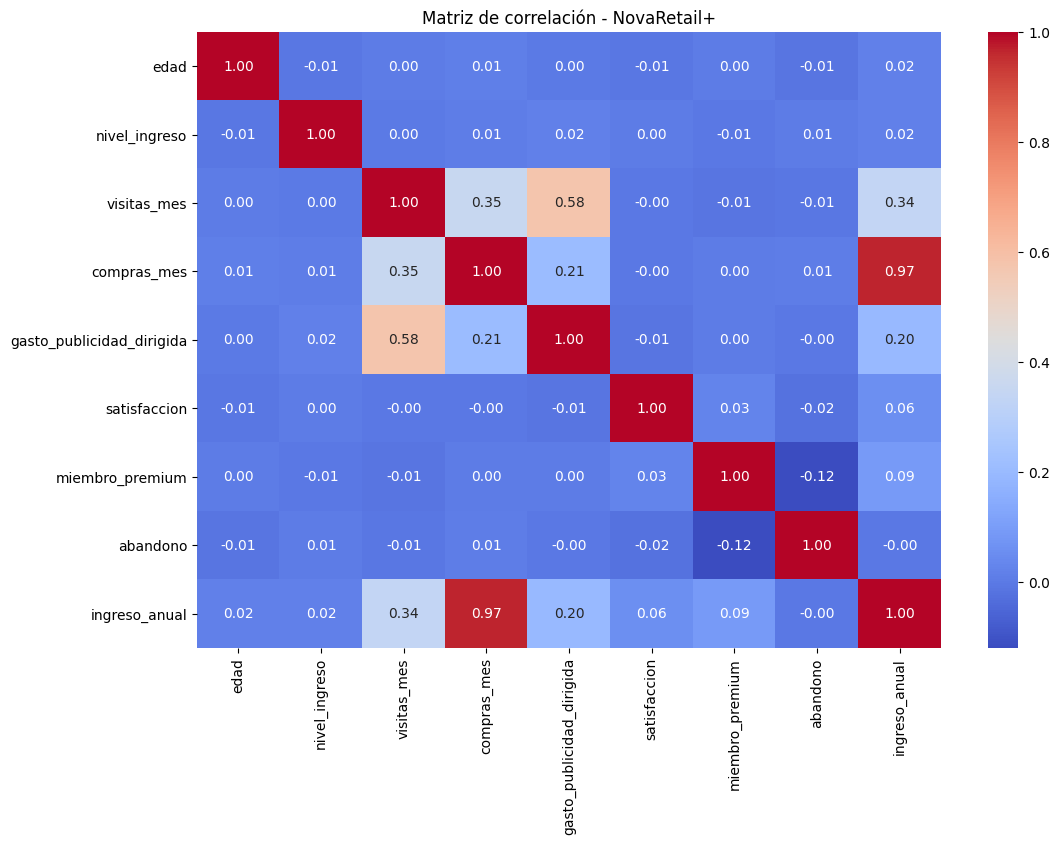

In [36]:
# Visualizar la matriz de correlación para identificar relaciones
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de correlación - NovaRetail+')
plt.show()

Observaciones generales (Heatmap)  
- Se observa que la mayoría de las variables presentan correlaciones débiles o prácticamente nulas, lo que indica que no existen relaciones lineales fuertes entre gran parte de ellas.
- La correlación positiva más fuerte se presenta entre compras_mes e ingreso_anual (r = 0.97), seguida de visitas_mes y gasto_publicidad_dirigida (r = 0.58).
- Se identifica una correlación positiva moderada entre visitas_mes y compras_mes (r = 0.35), lo que sugiere que los clientes que visitan más la plataforma tienden a realizar más compras.
- La relación entre miembro_premium y abandono es negativa y débil (r = -0.12), lo que indica que los clientes premium tienden a presentar una menor frecuencia de abandono.
- No se observan otras correlaciones negativas relevantes.


Observaciones respecto a `ingreso_anual`  
- Presenta una correlación positiva muy fuerte con compras_mes (r = 0.97), lo que indica que los clientes que realizan más compras mensuales tienden a generar mayores ingresos anuales para la empresa.
- Se observa una correlación positiva moderada con visitas_mes (r = 0.34), lo que sugiere una asociación entre la frecuencia de interacción con la plataforma y los ingresos generados.
- La correlación con gasto_publicidad_dirigida es positiva pero débil (r = 0.20), por lo que la inversión publicitaria presenta una asociación lineal limitada con los ingresos.
- Las variables miembro_premium (r = 0.09) y satisfaccion (r = 0.06) muestran asociaciones positivas muy débiles.
- Las variables edad y nivel_ingreso presentan correlaciones prácticamente nulas (r = 0.02), mientras que abandono muestra una correlación cercana a cero.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- Se decidió incluir un scatterplot entre compras_mes e ingreso_anual, debido a que estas variables presentan la correlación positiva más fuerte del heatmap (r = 0.97).
- El objetivo es visualizar la distribución de los datos, evaluar si la relación presenta una tendencia aproximadamente lineal e identificar posibles valores atípicos.
- Esta visualización permitirá complementar el análisis numérico de Pearson y verificar si la elevada correlación observada es consistente con el patrón gráfico.
- Es importante señalar que esta asociación no implica causalidad, especialmente porque la frecuencia de compras y los ingresos generados son variables económicamente relacionadas.

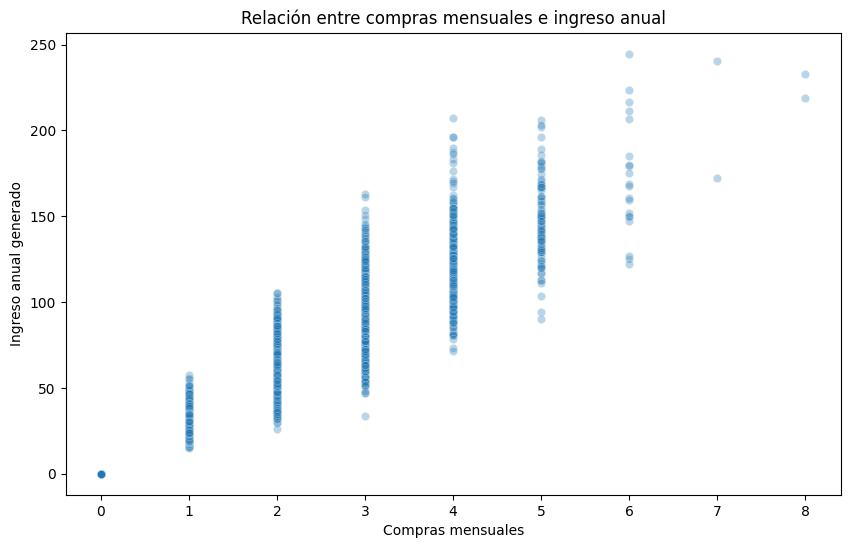

In [37]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='compras_mes',
    y='ingreso_anual',
    alpha=0.3
)

plt.title('Relación entre compras mensuales e ingreso anual')
plt.xlabel('Compras mensuales')
plt.ylabel('Ingreso anual generado')
plt.show()

### Scatterplot para pares clave

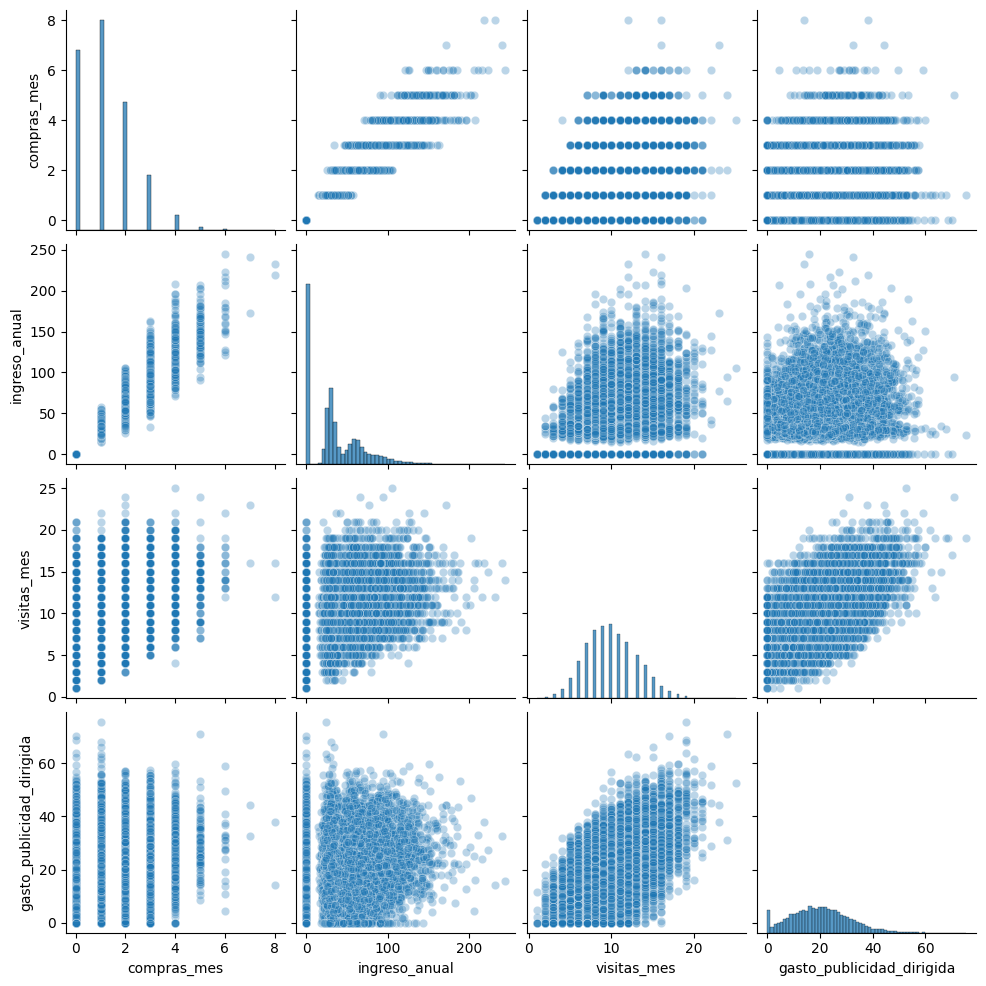

In [38]:
# Visualizar pares de variables con relaciones moderadas o fuertes
sns.pairplot(
    df[['compras_mes', 'ingreso_anual',
        'visitas_mes', 'gasto_publicidad_dirigida']],
    kind='scatter',
    plot_kws={'alpha': 0.3}
)

plt.show()

Observaciones iniciales (Scatterplot)

**compras_mes vs ingreso_anual**
- Dirección: Positiva muy fuerte (r = 0.97). A mayor número de compras mensuales, mayores ingresos anuales generados.
- Dispersión: Baja en relación con la tendencia general, aunque aumenta conforme crece el número de compras.
- Outliers: Se observan algunos clientes con ingresos superiores a 200, que podrían considerarse valores extremos y requieren una revisión adicional.
- Posible colinealidad: Muy alta, debido a la fuerte asociación entre ambas variables. Esto podría generar problemas de multicolinealidad si ambas se utilizaran como variables explicativas en un modelo predictivo.

**visitas_mes vs gasto_publicidad_dirigida**
- Dirección: Positiva relativamente fuerte (r = 0.58). Los clientes con más visitas tienden a presentar mayor gasto publicitario asignado.
- Dispersión: Media, con una tendencia ascendente visible, aunque los datos no se concentran completamente alrededor de una línea.
- Outliers: Se identifican algunos registros con gastos publicitarios superiores a 60 y otros con un número elevado de visitas.
- Posible colinealidad: Moderada. Existe una asociación relevante entre ambas variables que convendría evaluar si se utilizan conjuntamente en un modelo predictivo.

**visitas_mes vs compras_mes**
- Dirección: Positiva moderada (r = 0.35). Los clientes con más visitas tienden a realizar más compras.
- Dispersión: Media-alta, ya que clientes con una cantidad similar de visitas presentan diferentes frecuencias de compra.
- Outliers: Se observan algunos clientes con hasta 8 compras mensuales y otros con más de 20 visitas, aunque no necesariamente representan anomalías.
- Posible colinealidad: Baja a moderada. La asociación existe, pero no es lo suficientemente fuerte como para considerar que ambas variables contienen información redundante por sí sola.

**gasto_publicidad_dirigida vs ingreso_anual**
- Dirección: Positiva débil (r = 0.20). Una mayor inversión publicitaria presenta una asociación limitada con los ingresos generados.
- Dispersión: Alta, ya que los ingresos varían considerablemente entre clientes con niveles similares de gasto publicitario.
- Outliers: Se observan algunos clientes con ingresos superiores a 200 y otros con gastos publicitarios elevados.
- Posible colinealidad: Baja. La relación lineal entre ambas variables es débil.


## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [39]:
# Calcular correlación entre variables relevantes
variables = ['edad', 'nivel_ingreso', 'visitas_mes',
             'compras_mes', 'gasto_publicidad_dirigida',
             'satisfaccion', 'ingreso_anual']

correlacion_pearson = df[variables].corr(method='pearson')
print(correlacion_pearson)

                               edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000000      -0.009003     0.004998     0.014971   
nivel_ingreso             -0.009003       1.000000     0.001060     0.007309   
visitas_mes                0.004998       0.001060     1.000000     0.353844   
compras_mes                0.014971       0.007309     0.353844     1.000000   
gasto_publicidad_dirigida  0.000062       0.016834     0.578947     0.207528   
satisfaccion              -0.006963       0.002301    -0.003179    -0.003542   
ingreso_anual              0.017496       0.017446     0.337147     0.967149   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                        0.000062     -0.006963   
nivel_ingreso                               0.016834      0.002301   
visitas_mes                                 0.578947     -0.003179   
compras_mes                                 0.207528     -0.003542   
gasto_pub

In [40]:
# Calcular correlación entre variables relevantes
correlacion_spearman = df[variables].corr(method='spearman')
print(correlacion_spearman)

                               edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000000      -0.007775     0.005205     0.015630   
nivel_ingreso             -0.007775       1.000000     0.001420     0.009004   
visitas_mes                0.005205       0.001420     1.000000     0.332943   
compras_mes                0.015630       0.009004     0.332943     1.000000   
gasto_publicidad_dirigida  0.002869       0.015393     0.559267     0.192511   
satisfaccion              -0.007590       0.005243    -0.001305    -0.002006   
ingreso_anual              0.016097       0.025017     0.320954     0.967482   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                        0.002869     -0.007590   
nivel_ingreso                               0.015393      0.005243   
visitas_mes                                 0.559267     -0.001305   
compras_mes                                 0.192511     -0.002006   
gasto_pub

Observaciones de correlación

**compras_mes vs ingreso_anual**
- Correlación: Positiva muy fuerte, con Pearson = 0.9671 y Spearman = 0.9675.
- Magnitud: Ambos coeficientes son cercanos a 1, lo que indica una asociación muy fuerte. Los clientes que realizan más compras mensuales tienden a generar mayores ingresos anuales.
- Posible colinealidad: Existe una relación lineal muy elevada entre ambas variables. Sin embargo, dado que ingreso_anual es la variable objetivo, esta asociación no representa por sí misma un problema de multicolinealidad en un modelo donde compras_mes sea una variable explicativa.

**visitas_mes vs gasto_publicidad_dirigida**
- Correlación: Positiva moderada, con Pearson = 0.5789 y Spearman = 0.5593.
- Magnitud: Ambos coeficientes indican una asociación positiva relevante. Los clientes con más visitas mensuales tienden a presentar un mayor gasto publicitario asignado.
- Posible colinealidad: Existe cierta relación entre ambas variables explicativas, por lo que sería conveniente evaluar posibles problemas de multicolinealidad si se incluyen conjuntamente en un modelo predictivo.

**visitas_mes vs compras_mes**
- Correlación: Positiva moderada, con Pearson = 0.3538 y Spearman = 0.3329.
- Magnitud: La asociación es moderada. Los clientes que visitan más la plataforma tienden a realizar más compras, aunque la relación presenta una dispersión considerable.
- Posible colinealidad: Baja a moderada. Los coeficientes no sugieren una relación lineal suficientemente fuerte como para considerar que ambas variables sean redundantes.

**gasto_publicidad_dirigida vs ingreso_anual**
- Correlación: Positiva débil, con Pearson = 0.1975 y Spearman = 0.1850.
- Magnitud: La asociación es limitada. Una mayor inversión publicitaria tiende a relacionarse ligeramente con mayores ingresos, aunque existen diferencias importantes entre clientes.
- Posible colinealidad: La correlación entre ambas variables es baja. Además, al ser ingreso_anual la variable objetivo, esta relación no constituye por sí misma un problema de multicolinealidad.

### Punto-biserial

In [41]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr

# Correlación entre miembro_premium e ingreso_anual
corr_premium, p_premium = pointbiserialr(
    df['miembro_premium'], df['ingreso_anual']
)

# Correlación entre abandono e ingreso_anual
corr_abandono, p_abandono = pointbiserialr(
    df['abandono'], df['ingreso_anual']
)

print('Miembro premium:', corr_premium, 'p-value:', p_premium)
print('Abandono:', corr_abandono, 'p-value:', p_abandono)

Miembro premium: 0.0930994396198015 p-value: 3.0943076155242597e-30
Abandono: -0.002823934021617148 p-value: 0.7294691719078393


Observaciones Punto-biserial

**miembro_premium vs. ingreso_anual**
- Relación: Positiva de magnitud muy baja (r = 0.0931). Los clientes premium tienden a generar ingresos ligeramente mayores que los clientes sin membresía.
- Significancia estadística: El valor p (3.09 × 10⁻³⁰) es menor que 0.05, por lo que la asociación es estadísticamente significativa.
- Interpretación: Aunque existe una asociación positiva, su magnitud es muy débil, por lo que la membresía premium no presenta una relación fuerte con el ingreso anual generado.

**abandono vs. ingreso_anual**
- Relación: Negativa de magnitud prácticamente nula (r = -0.0028).
- Significancia estadística: El valor p (0.7295) es mayor que 0.05, por lo que la asociación no es estadísticamente significativa.
- Interpretación: No se encuentra evidencia estadística suficiente para afirmar que el abandono esté asociado con diferencias en el ingreso anual generado.


### V de Cramér

In [42]:

# Función para calcular V de Cramér

from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

def cramers_v(df, col1, col2):
    # Crear tabla de contingencia
    tabla = pd.crosstab(df[col1], df[col2])

    # Calcular Chi-cuadrado
    chi2, p, dof, expected = chi2_contingency(tabla)

    # Obtener total de observaciones
    n = tabla.to_numpy().sum()

    # Calcular V de Cramér
    r, k = tabla.shape
    v = np.sqrt(chi2 / (n * min(r - 1, k - 1)))

    return v

In [43]:
# Aplicar V de Cramér en variables relevantes

v_dispositivo_region = cramers_v(df, 'tipo_dispositivo', 'region')

print('V de Cramér (tipo_dispositivo vs region):', v_dispositivo_region)

V de Cramér (tipo_dispositivo vs region): 0.012378338407739397


Observaciones V de Cramér
- El análisis entre tipo_dispositivo y region presenta un coeficiente V de Cramér de 0.0124, lo que indica una asociación prácticamente nula entre ambas variables categóricas. Este resultado sugiere que el tipo de dispositivo utilizado por los clientes no presenta una relación relevante con su región geográfica. Debido a que el coeficiente es muy cercano a cero, no se identifican patrones de asociación importantes que justifiquen una segmentación basada exclusivamente en la combinación de estas dos variables.



## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---



### Hallazgo 1 — Las compras mensuales presentan la asociación más fuerte con el ingreso anual

**Evidencia visual:**   
- En el gráfico de dispersión entre compras_mes e ingreso_anual se observa una tendencia positiva claramente definida. A medida que aumenta el número de compras mensuales, también tiende a incrementarse el ingreso anual generado por los clientes.

**Evidencia numérica:** 
- Correlación de Pearson: 0.9671
- Correlación de Spearman: 0.9675
- Ambos coeficientes muestran una asociación positiva muy fuerte y consistente entre las variables.

**Interpretación**  
- Los clientes que realizan más compras mensuales tienden a generar mayores ingresos anuales para NovaRetail+. La similitud entre los coeficientes de Pearson y Spearman refuerza la consistencia de esta asociación.

**No podemos afirmar**  
- No podemos concluir que aumentar la frecuencia de compra provoque automáticamente un incremento proporcional en los ingresos. Tampoco podemos asegurar que esta relación sea independiente de otros factores, como el valor promedio de las compras o las características de los clientes. Además, dado que el ingreso generado está directamente relacionado con las transacciones realizadas, parte de esta asociación podría deberse a la propia forma en que se calcula ingreso_anual.

**Implicación de negocio**  
- NovaRetail+ podría utilizar la frecuencia de compra como un indicador prioritario para identificar segmentos de clientes con mayor generación de ingresos. Se recomienda analizar los patrones de compra y explorar estrategias de fidelización y recompra, evaluando posteriormente su efectividad mediante pruebas controladas antes de atribuirles un impacto en los ingresos



### Hallazgo 2 — Las visitas mensuales presentan una asociación positiva moderada con el ingreso anual

**Evidencia visual:**  
- En el gráfico de dispersión entre visitas_mes e ingreso_anual se observa una tendencia positiva, aunque con una dispersión considerable. Los clientes con mayor número de visitas mensuales tienden a generar ingresos más altos, pero existen diferencias importantes entre clientes con niveles similares de actividad.

**Evidencia numérica:** 
- Correlación de Pearson: 0.3371
- Correlación de Spearman: 0.3210
- Ambos coeficientes indican una asociación positiva de magnitud moderada entre las visitas mensuales y el ingreso anual.

**Interpretación**  
- Los clientes que visitan la plataforma con mayor frecuencia tienden a generar mayores ingresos para NovaRetail+. Sin embargo, la asociación es considerablemente menor que la observada entre las compras mensuales y el ingreso anual, lo que sugiere que una mayor actividad en la plataforma no necesariamente se traduce en mayores ingresos.

**No podemos afirmar**  
- No podemos concluir que incrementar las visitas mensuales provoque directamente un aumento en los ingresos. Tampoco podemos asegurar que todos los clientes con mayor frecuencia de visitas realicen más compras, ya que pueden existir otros factores que influyan en su comportamiento.

**Implicación de negocio**  
- NovaRetail+ podría utilizar la frecuencia de visitas como un indicador complementario para identificar clientes activos y detectar oportunidades de conversión.Se recomienda analizar especialmente a los clientes que visitan frecuentemente la plataforma, pero realizan pocas compras, con el objetivo de identificar posibles barreras en el proceso de compra y diseñar estrategias que posteriormente puedan evaluarse mediante pruebas controladas.



### Hallazgo 3 — El gasto en publicidad dirigida presenta una asociación positiva débil con el ingreso anual

**Evidencia visual:**  
- En el gráfico de dispersión entre gasto_publicidad_dirigida e ingreso_anual se observa una ligera tendencia positiva, aunque con una dispersión considerable de los datos. Los clientes con mayor gasto en publicidad dirigida tienden a generar ingresos ligeramente superiores, pero existen diferencias importantes entre clientes con niveles similares de inversión publicitaria.

**Evidencia numérica:** 
- Correlación de Pearson: 0.1975
- Correlación de Spearman: 0.1850
- Ambos coeficientes muestran una asociación positiva débil entre el gasto en publicidad dirigida y el ingreso anual generado.

**Interpretación**  
- Los resultados sugieren que existe una relación positiva, aunque limitada, entre el gasto en publicidad dirigida y los ingresos anuales de los clientes. La baja magnitud de los coeficientes indica que el gasto publicitario, analizado individualmente, tiene una asociación mucho menor con los ingresos que variables como la frecuencia de compra o las visitas mensuales.

**No podemos afirmar**  
- No podemos concluir que aumentar el gasto en publicidad dirigida genere directamente mayores ingresos, ni que una mayor inversión publicitaria garantice mejores resultados comerciales. Tampoco podemos determinar la rentabilidad de la publicidad o su retorno de inversión (ROI) únicamente a partir de estos coeficientes de correlación.

**Implicación de negocio**  
- NovaRetail+ podría revisar sus estrategias de publicidad dirigida para identificar segmentos de clientes en los que la inversión publicitaria esté asociada con mejores resultados comerciales. Se recomienda complementar el análisis con indicadores como la tasa de conversión, el costo de adquisición de clientes y el retorno de inversión publicitaria (ROAS), así como realizar pruebas controladas para evaluar el impacto real de las campañas. Esto permitiría orientar las decisiones de inversión publicitaria hacia estrategias respaldadas por evidencia, en lugar de asumir que un mayor gasto necesariamente produce mayores ingresos.



### Hallazgo 4 — La membresía premium presenta una asociación positiva muy débil con el ingreso anual

**Evidencia visual:**  
- En esta sección no se elaboró un gráfico específico para comparar los ingresos anuales entre clientes premium y no premium. Por lo tanto, el hallazgo se fundamenta principalmente en los resultados de la correlación punto-biserial.

**Evidencia numérica:** 
- Correlación punto-biserial: 0.0931
- Valor p: 3.09 × 10⁻³⁰
- Proporción de clientes premium: 13.93%
- El coeficiente indica una asociación positiva muy débil, mientras que el valor p, inferior a 0.05, señala que esta asociación es estadísticamente significativa.

**Interpretación**  
- Los clientes con membresía premium tienden a generar ingresos anuales ligeramente superiores a los clientes sin membresía. Sin embargo, la magnitud de la asociación es muy baja, lo que indica que la membresía premium, considerada de manera individual, presenta una relación limitada con los ingresos generados. Este resultado demuestra que una asociación puede ser estadísticamente significativa sin necesariamente representar una diferencia importante desde el punto de vista comercial.

**No podemos afirmar**  
- No podemos concluir que adquirir una membresía premium provoque un incremento en los ingresos anuales de los clientes. Tampoco podemos asegurar que la membresía sea una estrategia rentable o que incrementar el número de suscriptores premium genere automáticamente mayores ingresos. La diferencia observada podría estar relacionada con otros factores, como la frecuencia de compra, los hábitos de consumo o las características de los clientes que deciden adquirir la membresía.

**Implicación de negocio**  
- NovaRetail+ podría realizar un análisis más detallado de los clientes premium y no premium para identificar diferencias en sus patrones de compra, frecuencia de visitas y generación de ingresos. Se recomienda evaluar la rentabilidad del programa de membresías considerando los ingresos adicionales, los costos asociados y la retención de clientes. Antes de ampliar la inversión en el programa premium, sería conveniente realizar pruebas controladas que permitan determinar si la membresía produce beneficios comerciales medibles.


### Hallazgo 5 — El abandono de clientes no presenta una asociación significativa con el ingreso anual

**Evidencia visual:**  
- En esta sección no se elaboró un gráfico específico para comparar los ingresos anuales entre clientes que abandonaron y aquellos que permanecieron activos. Por lo tanto, el hallazgo se fundamenta principalmente en los resultados del análisis de correlación punto-biserial.

**Evidencia numérica:** 
- Correlación punto-biserial: -0.0028
- Valor p: 0.7295
- Proporción de clientes con abandono: 15.07%
- El coeficiente es prácticamente cero y el valor p es superior a 0.05, por lo que no se identifica una asociación estadísticamente significativa entre el abandono y el ingreso anual.

**Interpretación**  
- Los resultados muestran que el abandono de clientes no presenta una asociación lineal relevante con el ingreso anual generado en el conjunto de datos analizado. Aunque el coeficiente tiene signo negativo, su magnitud es tan pequeña que no representa una relación negativa relevante. Esto sugiere que, en este análisis, los clientes clasificados como abandonados no presentan una diferencia sistemática importante en sus ingresos anuales respecto a los clientes que permanecen activos.

**No podemos afirmar**  
- No podemos concluir que el abandono de clientes no tenga consecuencias económicas para NovaRetail+. Tampoco podemos asegurar que prevenir el abandono carezca de beneficios comerciales, ya que el análisis considera los ingresos anuales registrados y no necesariamente las pérdidas futuras asociadas con la salida de clientes. Además, no podemos descartar que existan diferencias relevantes en determinados segmentos de clientes o que otras variables influyan en la relación.

**Implicación de negocio**  
- NovaRetail+ no debería interpretar la ausencia de correlación como una razón para reducir sus esfuerzos de retención. Se recomienda analizar el abandono por segmentos, considerando variables como la frecuencia de compra, la membresía premium y los ingresos históricos. También sería conveniente evaluar el valor de vida del cliente (Customer Lifetime Value o CLV) y la evolución de los ingresos antes y después del abandono. Esto permitiría identificar qué grupos de clientes representan un mayor riesgo económico y orientar las estrategias de retención hacia aquellos con mayor valor potencial.

### **Limitaciones**
- Correlación ≠ causalidad: Las asociaciones identificadas no permiten afirmar que una variable provoque cambios en otra. Para establecer relaciones causales sería necesario realizar análisis adicionales o experimentos controlados.
- Análisis de un periodo específico: El conjunto de datos corresponde a 2024, por lo que los resultados describen las relaciones observadas durante ese periodo y no necesariamente representan el comportamiento de los clientes en otros años.
- Variables no consideradas: Pueden existir factores adicionales que influyan en los ingresos, como descuentos, promociones, categorías de productos, valor promedio de compra y antigüedad del cliente.
- Limitaciones de las correlaciones: Pearson mide asociaciones lineales y Spearman asociaciones monotónicas. Por lo tanto, estos métodos pueden no detectar relaciones más complejas entre las variables.
- Relación entre compras e ingresos: La correlación extremadamente alta entre compras_mes e ingreso_anual podría estar parcialmente relacionada con la forma en que se calcula el ingreso generado. Por ello, no debe interpretarse automáticamente como un efecto causal independiente.
- Ausencia de análisis por segmentos: Las correlaciones generales pueden ocultar diferencias importantes entre grupos de clientes, como usuarios premium y no premium, regiones o tipos de dispositivo.
- Falta de evaluación de rentabilidad: El análisis permite identificar asociaciones con los ingresos, pero no determina la rentabilidad de las campañas publicitarias, los costos de retención ni el valor de vida del cliente.

### **Próximos pasos** 

Paso 1 — Profundizar en la segmentación de clientes
- Comparar los patrones de compra y los ingresos anuales entre clientes premium y no premium.
- Analizar diferencias por región y tipo de dispositivo para identificar segmentos con comportamientos particulares.
- Identificar clientes con muchas visitas mensuales, pero pocas compras, para detectar oportunidades de mejora en la conversión.
  
Paso 2 — Evaluar el desempeño comercial y la rentabilidad
- Analizar la relación entre el gasto en publicidad dirigida, las compras realizadas y los ingresos generados, controlando otras variables relevantes.
- Incorporar indicadores como tasa de conversión, ticket promedio y retorno de inversión publicitaria (ROAS).
- Estudiar el comportamiento de los clientes que abandonan la plataforma y estimar su valor de vida (CLV) para identificar segmentos prioritarios de retención.

Paso 3 — Validar hallazgos y evaluar estrategias
- Desarrollar un modelo estadístico multivariable para evaluar las asociaciones entre los comportamientos de los clientes y los ingresos, considerando simultáneamente distintos factores.
- Diseñar pruebas A/B para evaluar estrategias de recompra, personalización y publicidad dirigida antes de implementarlas a gran escala.
- Establecer un seguimiento periódico de indicadores clave (KPIs) para medir resultados, detectar cambios en el comportamiento de los clientes y ajustar las estrategias comerciales.